# CCD height map: sign convention and the Z4 it adds (v1)

**Author:** Aaron Roodman (prepared by Claude)  
**Date Created:** 2026-10-24  
**Last Modified:** 2026-10-24  
**Status:** In Progress  
**Keywords:** CCD height map, Z4, defocus, corner wavefront sensor, batoid, ts_wep, metrology  

## Description

Checks, from the raw metrology and from batoid, which way a positive value in the CCD height
map points, and the sign of the Z4 a height adds. The test fact: on the corner wavefront
sensors (CWFS), SW1 is intra-focal (high) and SW0 extra-focal (low), at ±1.5 mm.

1. The raw metrology pistons of SW0 and SW1, so the sign of "intra" in the map's frame is read
   off the data.
2. The batoid frame: which way the Detector's +z points, and the Z4 of a ±1.5 mm shift (ts_wep's
   intra/extra convention).
3. The batoid_rubin height map against the metrology, after the ±1.5 mm piston is removed.
4. The Z4 batoid gets from the height map on each corner sensor, against the
   `ts_intrinsic_wavefront` term `+15 µm/mm × h`.

**Output:** printed tables only  
**References:** `notes/status/phase6_ccd_height_sign.md`; `aos/docs/ts_wep_zernike_intrinsics.md` §3;
`ts_intrinsic_wavefront` `ccd_height.py`

## Parameters

In [1]:
import os

# Raw SLAC metrology (per-sensor BinTableHDUs with X_CCS, Y_CCS, Z_CCS_MODEL, Z_CCS_MEASURED)
METROLOGY_FITS = 'LSST_FP_cold_b_measurement_4col_bysurface.fits'
# batoid_rubin per-detector height map (ccd_height_map.fits.gz)
HEIGHT_MAP_DIR = os.path.expanduser('~/u/LSST/packages/batoid_rubin_data/ccd_height_map')
BAND = 'r'
CORNERS = ['R00', 'R04', 'R40', 'R44']
# FAM nights for the Z4-against-height check (danish_1_2, current build)
FAM_VARIANT = 'danish_1_2'
FAM_NIGHTS = [20251109, 20251110, 20251111, 20251112]


## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import batoid
from astropy.io import fits
from batoid_rubin.builder import det_height_maps
from lsst.ts.wep.instrument import Instrument
from lsst.ts.intrinsic.wavefront import ccd_height as ch

inst = Instrument(configFile='policy:instruments/LsstCam.yaml')
tel = inst.getBatoidModel(BAND)
wl = inst.wavelength[BAND]
eps = tel.pupilObscuration
maps = det_height_maps(HEIGHT_MAP_DIR)
print(f'band {BAND}, wavelength {wl*1e9:.0f} nm, obscuration {eps:.3f} (dimensionless), '
      f'defocalOffset {inst.defocalOffset*1e3:.2f} mm')

def z4_ta(optic, thx, thy):
    """Z4 [µm of wavefront] from batoid.zernikeTA (annular Noll, ts_wep's estimator)."""
    return batoid.zernikeTA(optic, thx, thy, wl, eps=eps, jmax=4, nrad=20, naz=120)[4] * wl * 1e6

band r, wavelength 619 nm, obscuration 0.612 (dimensionless), defocalOffset 1.50 mm


## 1. Raw metrology: which sign is intra-focal?

Median `Z_CCS_MEASURED` per corner-sensor half, as stored in the file (mm). No piston removed.

In [3]:
rows = []
with fits.open(METROLOGY_FITS) as h:
    for hdu in h[1:]:
        if 'WFS' in hdu.name or hdu.name == 'R22S11':
            rows.append((hdu.name, float(np.median(hdu.data['Z_CCS_MEASURED']))))
met = pd.DataFrame(rows, columns=['sensor', 'median Z_CCS_MEASURED [mm]'])
met

,sensor,median Z_CCS_MEASURED [mm]
0,R00WFS0,1.499184
1,R00WFS1,-1.502338
2,R04WFS0,1.501678
3,R04WFS1,-1.501853
4,R22S11,0.005289
5,R40WFS0,1.502409
6,R40WFS1,-1.508552
7,R44WFS0,1.496810
8,R44WFS1,-1.499044


WFS0 (= SW0, extra-focal) sits at +1.5 mm and WFS1 (= SW1, intra-focal, high) at −1.5 mm.
**So in this file a negative value is toward intra-focal (high), and a positive value toward
extra-focal (low).**

### Height maps

Left: the whole focal plane, `Z_CCS_MEASURED` with the ±1.5 mm WFS piston removed, in µm.
Right: the four corner rafts as stored, piston included, in mm. Axes are the file's `X_CCS`,
`Y_CCS` (mm). Red is positive `Z_CCS_MEASURED`.

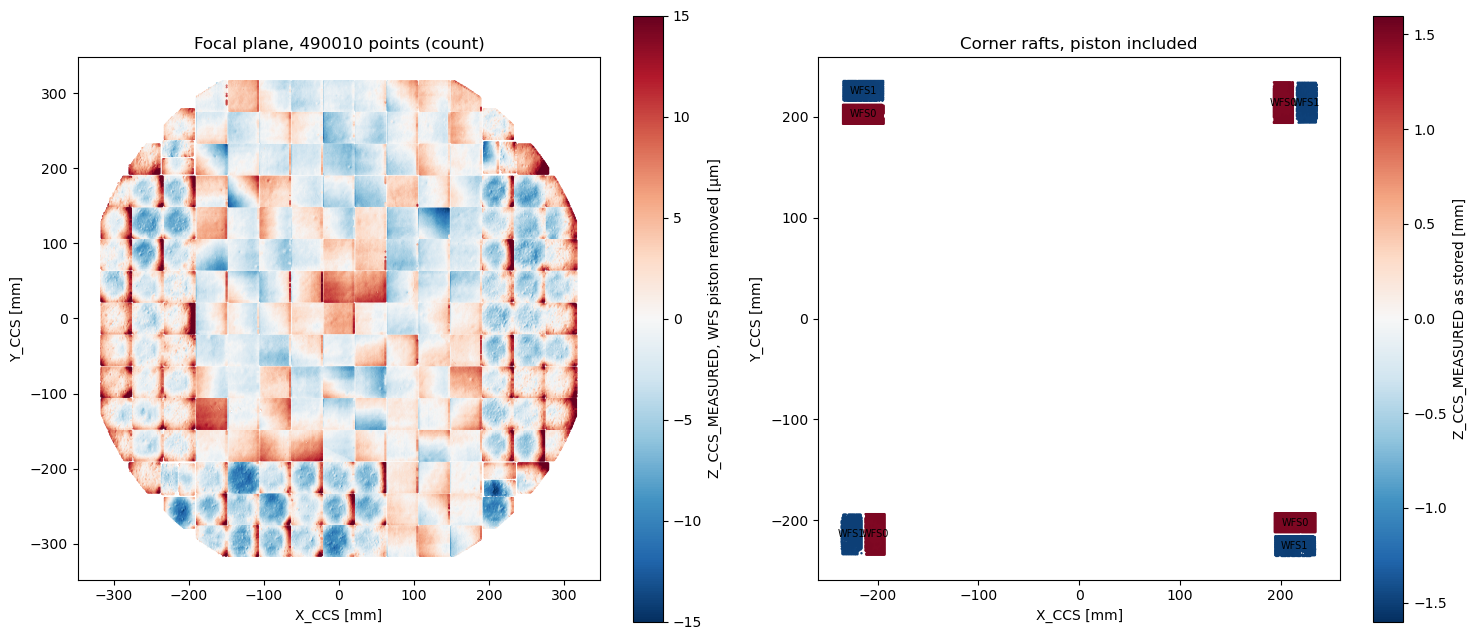

In [4]:
import matplotlib.pyplot as plt

xs, ys, zs, zraw = [], [], [], []
with fits.open(METROLOGY_FITS) as h:
    for hdu in h[1:]:
        if hdu.name == 'ALL_SURFACES':   # every point again, WFS piston included
            continue
        d = hdu.data
        piston = {'WFS0': 1.5, 'WFS1': -1.5}.get(hdu.name[3:], 0.0)
        xs.append(d['X_CCS']); ys.append(d['Y_CCS'])
        zs.append((d['Z_CCS_MEASURED'] - piston) * 1e3)
        zraw.append(np.where('WFS' in hdu.name, d['Z_CCS_MEASURED'], np.nan))
xs, ys, zs, zraw = map(np.concatenate, (xs, ys, zs, zraw))

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
sc = ax[0].scatter(xs, ys, c=zs, s=0.2, cmap='RdBu_r', vmin=-15, vmax=15, rasterized=True)
fig.colorbar(sc, ax=ax[0], label='Z_CCS_MEASURED, WFS piston removed [µm]')
ax[0].set_title(f'Focal plane, {len(zs)} points (count)')
w = np.isfinite(zraw)
sc = ax[1].scatter(xs[w], ys[w], c=zraw[w], s=0.5, cmap='RdBu_r', vmin=-1.6, vmax=1.6,
                   rasterized=True)
fig.colorbar(sc, ax=ax[1], label='Z_CCS_MEASURED as stored [mm]')
ax[1].set_title('Corner rafts, piston included')
with fits.open(METROLOGY_FITS) as h:
    for hdu in h[1:]:
        if 'WFS' in hdu.name:
            ax[1].text(np.median(hdu.data['X_CCS']), np.median(hdu.data['Y_CCS']),
                       hdu.name[3:], ha='center', va='center', fontsize=7)
for a in ax:
    a.set_aspect('equal'); a.set_xlabel('X_CCS [mm]'); a.set_ylabel('Y_CCS [mm]')
plt.tight_layout()

### Andy Rasmussen's "image height" comment

`fp_metro_arasmus_210211` says: "The sense of the focal plane image height here is in the
opposite direction from the direction of Z in the Camera Coordinate System (ZCCS)." LCA-13381
puts +Z_CCS away from L3, toward the focal plane. So Andy's **image height** is positive toward
L3: high, intra-focal.

The FITS columns are not that image height. They are named `Z_CCS_MEASURED` and
`Z_CCS_MODEL`, and the data follow Z_CCS. WFS1 (= SW1, intra, high) sits at −1.5 mm, which is
toward L3 under LCA-13381. If the columns held Andy's image height, SW1 would be at +1.5 mm.
The headers say only that the columns are relative to the best-fit plane of the raft surfaces;
they do not flip the sign.

The two readings fit together: image height = −Z_CCS. The document's plots of image height
show high as positive. The file, and the batoid_rubin map made from it, store Z_CCS, where
positive is low (extra-ward).

The WFS0/WFS1 → SW0/SW1 mapping is checked against obs_lsst: the file's X_CCS is the
focal-plane y of `lsst.obs.lsst.LsstCam`. R00WFS1 is at X_CCS = −225.9 mm, and R00_SW1's
center is at focal-plane y = −225.9 mm.

## 2. The batoid frame and ts_wep's intra/extra Z4

Which way the Detector's local +z points relative to the light, and Z4 at a field point for the ts_wep defocal shifts.

In [5]:
det = tel['Detector']
r = batoid.RayVector.fromStop(0, 0, tel, wavelength=wl, theta_x=0, theta_y=np.deg2rad(0.5))
tel.trace(r)
print(f'Detector at global z {det.coordSys.origin[2]:.5f} m, local zhat {det.coordSys.zhat}; '
      f'L3 exit at global z {tel["L3_exit"].coordSys.origin[2]:.5f} m')
print(f'chief ray direction at the detector (global): vz = {r.vz[0]:+.4f} (light travels +z)')
for sign, label in [(+1, 'extra (ts_wep sign +1)'), (-1, 'intra (ts_wep sign -1)')]:
    shifted = tel.withLocallyShiftedOptic('Detector', [0, 0, sign * inst.defocalOffset])
    print(f'{label:24s}: Detector shifted {sign*inst.defocalOffset*1e3:+.1f} mm, '
          f'Z4 = {z4_ta(shifted, 0, np.deg2rad(0.5)):+.3f} µm of wavefront')

Detector at global z 4.42942 m, local zhat [0. 0. 1.]; L3 exit at global z 4.40092 m
chief ray direction at the detector (global): vz = +0.9994 (light travels +z)
extra (ts_wep sign +1)  : Detector shifted +1.5 mm, Z4 = +23.797 µm of wavefront
intra (ts_wep sign -1)  : Detector shifted -1.5 mm, Z4 = -23.766 µm of wavefront


Light travels +z, so +z is away from L3. ts_wep's extra-focal shift is +1.5 mm (Z4 > 0); intra
is −1.5 mm, toward L3 (high), with Z4 < 0. This matches the metrology: SW0 at +1.5 mm, SW1 at
−1.5 mm. **An intra-focal (high) displacement gives negative Z4.**

## 3. The batoid_rubin height map against the metrology

`ts_intrinsic_wavefront.ccd_height.make_metrology_table` removes the ±1.5 mm piston from the WFS halves. Compare the result with the batoid map at the same points.

In [6]:
t = ch.make_metrology_table(METROLOGY_FITS)
dets = np.asarray(t['det']).astype(str)
keep = np.isin(dets, [f'{c}_{s}' for c in CORNERS for s in ('SW0', 'SW1')] + ['R22_S11', 'R11_S11', 'R33_S22'])
fx, fy, zm, dd = (np.asarray(t['fpx'])[keep], np.asarray(t['fpy'])[keep],
                  np.asarray(t['z_meas'])[keep], dets[keep])
hb = ch._sag_oriented(maps, fx, fy, dd, *ch.BATOID_FP_ORIENTATION)
ok = np.isfinite(hb)
slope = np.polyfit(zm[ok], hb[ok], 1)[0]
print(f'{ok.sum()} points (count): slope batoid/metrology = {slope:+.3f} (dimensionless); '
      f'RMS(batoid - metrology) = {np.std(hb[ok]-zm[ok])*1e3:.2f} µm, '
      f'RMS(batoid + metrology) = {np.std(hb[ok]+zm[ok])*1e3:.2f} µm')
pd.DataFrame([(d, np.median(zm[ok & (dd == d)])*1e3, np.median(hb[ok & (dd == d)])*1e3)
              for d in np.unique(dd)],
             columns=['detector', 'metrology h [µm]', 'batoid map h [µm]'])

17391 points (count): slope batoid/metrology = +0.949 (dimensionless); RMS(batoid - metrology) = 0.95 µm, RMS(batoid + metrology) = 8.37 µm


,detector,metrology h [µm],batoid map h [µm]
0,R00_SW0,-0.815988,-0.733896
1,R00_SW1,-2.338052,-2.510238
2,R04_SW0,1.677990,1.720926
3,R04_SW1,-1.852989,-1.772007
4,R11_S11,-0.195000,-0.244078
5,R22_S11,5.289500,5.342823
6,R33_S22,-1.003000,-1.035591
7,R40_SW0,2.408981,2.359478
8,R40_SW1,-8.552015,-8.577557
9,R44_SW0,-3.189981,-3.308725


The batoid map has the metrology's sign (slope +0.95; flipping it raises the RMS from about
1 µm to about 8 µm). **So the height map inherits the metrology convention: positive h is
toward extra-focal (low), negative h toward intra-focal (high).** batoid applies it with
`withPerturbedSurface('Detector', ...)`, as a sag along the Detector's +z, the same direction.

## 4. The Z4 a height adds, per corner sensor

For each corner sensor, a field point whose chief ray lands at the map center; SW0 traced extra (+1.5 mm), SW1 intra (−1.5 mm). dZ4 (batoid) = Z4 with the map minus without. dZ4 (pipeline) = `+15 µm/mm × h`, what `compute_ccd_heights` returns as `Z4_height`.

In [7]:
def land(optic, th):
    r = batoid.RayVector.fromStop(0, 0, optic, wavelength=wl, theta_x=th[0], theta_y=th[1])
    optic.trace(r)
    return np.array([r.x[0], r.y[0]])

rows = []
for raft in CORNERS:
    for side, sw, sign in [('extra', 'SW0', +1), ('intra', 'SW1', -1)]:
        m = maps[f'{raft}_{sw}']
        target = np.array([0.5*(m.xs[0]+m.xs[-1]), 0.5*(m.ys[0]+m.ys[-1])])
        shifted = tel.withLocallyShiftedOptic('Detector', [0, 0, sign*inst.defocalOffset])
        th = target / 10.31                   # plate scale ~10.31 m/rad, then Newton steps
        for _ in range(8):
            p = land(shifted, th)
            if np.hypot(*(p - target)) < 1e-7:
                break
            J = np.column_stack([(land(shifted, th + d) - p) / 1e-6 for d in np.eye(2)*1e-6])
            th = th + np.linalg.solve(J, target - p)
        h_mm = float(m.sag(*land(shifted, th))) * 1e3
        withmap = tel.withPerturbedSurface('Detector', m).withLocallyShiftedOptic(
            'Detector', [0, 0, sign*inst.defocalOffset])
        dz_b = (z4_ta(withmap, *th) - z4_ta(shifted, *th)) * 1e3
        dz_p = ch.HEIGHT_TO_Z4_UM_PER_MM * h_mm * 1e3
        rows.append((raft, sw, side, h_mm*1e3, dz_b, dz_p, dz_b/dz_p))
res = pd.DataFrame(rows, columns=['raft', 'sensor', 'side', 'h [µm]', 'dZ4 batoid [nm]',
                                  'dZ4 pipeline [nm]', 'batoid/pipeline'])
res

,raft,sensor,side,h [µm],dZ4 batoid [nm],dZ4 pipeline [nm],batoid/pipeline
0,R00,SW0,extra,-4.362393,-69.680151,-65.435897,1.064861
1,R00,SW1,intra,-4.308052,-68.609228,-64.620776,1.061721
2,R04,SW0,extra,-1.899075,-30.357587,-28.486132,1.065697
3,R04,SW1,intra,-5.451428,-86.827615,-81.771421,1.061833
4,R40,SW0,extra,-0.777891,-12.429319,-11.668372,1.065214
5,R40,SW1,intra,-11.678024,-186.069137,-175.170363,1.062218
6,R44,SW0,extra,-6.490471,-103.643008,-97.357059,1.064566
7,R44,SW1,intra,-1.300410,-20.739245,-19.506147,1.063216


## 5. FAM Z4 against the height

The measured wavefront should follow the height: a sensor point moved by h changes Z4 by about
15.8 nm per µm of height. The full-array mode (FAM) table measures Z4 at every donut on the
science sensors. A k≤6 double-Zernike fit per visit (the stored `z1toz6_z4_c1..6`) removes the
smooth field dependence, leaving the local part, which the height should drive.

For each donut: residual Z4 = `zk_OCS[Z4]` − the k≤6 fit at its field angle (µm of wavefront;
Z4 does not change between OCS and CCS). Height h = `Z_CCS_MEASURED` at the donut's
focal-plane position, the median of the 8 nearest metrology points. The file's `X_CCS` is the
obs_lsst focal-plane y, and `Y_CCS` the focal-plane x. Corner sensors are not in the table.

In [8]:
import pyarrow.dataset as pads
import pyarrow.parquet as pq
import statsmodels.api as sm
from scipy.spatial import cKDTree
from scipy.stats import pearsonr, spearmanr
from lsst.afw.cameraGeom import FOCAL_PLANE, PIXELS
from lsst.obs.lsst import LsstCam
from lsst.ts.intrinsic.wavefront.dz_fitting import focal_plane_zernike_basis
from rubinwork.common.utils import nmad
from rubinwork.products import catalog

fam_dir = catalog.path('fam_tables', FAM_VARIANT)
kcols = [f'z1toz6_z4_c{k}' for k in range(1, 7)]
fit = pq.read_table(f'{fam_dir}/fits.parquet',
                    columns=['day_obs', 'seq_num', 'bad_fit'] + kcols).to_pandas()
don = pads.dataset(f'{fam_dir}/donuts.parquet').to_table(
    columns=['day_obs', 'seq_num', 'detector', 'centroid_x', 'centroid_y', 'thx_OCS', 'thy_OCS',
             'used', 'zk_OCS', 'zk_intrinsic_OCS'],
    filter=pads.field('day_obs').isin(FAM_NIGHTS)).to_pandas()
don['z4'] = [z[0] for z in don.pop('zk_OCS')]                  # nollIndices start at 4
don['z4_intrinsic'] = [z[0] for z in don.pop('zk_intrinsic_OCS')]
don = don.merge(fit, on=['day_obs', 'seq_num'])
don = don[don.used & ~don.bad_fit].reset_index(drop=True)
basis, _ = focal_plane_zernike_basis(np.rad2deg(don.thx_OCS.values), np.rad2deg(don.thy_OCS.values), 6)
don['z4_resid'] = don.z4 - np.einsum('ij,ij->i', basis, don[kcols].values)

cam = LsstCam.getCamera()
fp = np.full((len(don), 2), np.nan)
for det, g in don.groupby('detector'):
    tx = cam[det].getTransform(PIXELS, FOCAL_PLANE).getMapping()
    fp[g.index] = tx.applyForward(np.vstack([g.centroid_x, g.centroid_y])).T
don['fpx'], don['fpy'] = fp[:, 0], fp[:, 1]

mx, my, mz = [], [], []
with fits.open(METROLOGY_FITS) as h:
    for hdu in h[1:]:
        if hdu.name == 'ALL_SURFACES' or 'WFS' in hdu.name:
            continue
        mx.append(hdu.data['X_CCS']); my.append(hdu.data['Y_CCS']); mz.append(hdu.data['Z_CCS_MEASURED'])
mx, my, mz = map(np.concatenate, (mx, my, mz))
tree = cKDTree(np.c_[mx, my])

def height_um(x_ccs, y_ccs):
    dist, idx = tree.query(np.c_[x_ccs, y_ccs], k=8)
    return np.median(mz[idx], axis=1) * 1e3, dist[:, 0]

don['h_um'], dist = height_um(don.fpy, don.fpx)
don = don[dist < 1.0]                      # mm; drops donuts off the metrology grid

def report(label, h, z):
    huber = sm.RLM(z, sm.add_constant(h), M=sm.robust.norms.HuberT()).fit()
    print(f'{label}: n = {len(h)} donuts (count), Pearson r = {pearsonr(h, z)[0]:+.3f}, '
          f'Spearman rho = {spearmanr(h, z)[0]:+.3f} (dimensionless); Huber slope = '
          f'{huber.params[1]*1e3:+.2f} nm of Z4 per µm of height')
    return huber

print(f'{FAM_VARIANT} {catalog.manifest("fam_tables", FAM_VARIANT)["build"]}, nights {FAM_NIGHTS}')
huber = report('measured Z4 minus k<=6 fit against h', don.h_um.values, don.z4_resid.values)
report('batoid intrinsic Z4 (with height maps) against h', don.h_um.values, don.z4_intrinsic.values)
h_swap, _ = height_um(don.fpx, don.fpy)
report('control, metrology X and Y swapped', h_swap, don.z4_resid.values)
print(f'residual Z4 nMAD {nmad(don.z4_resid)*1e3:.1f} nm; after removing the height line '
      f'{nmad(don.z4_resid - huber.predict(sm.add_constant(don.h_um.values)))*1e3:.1f} nm')

danish_1_2 20261014, nights [20251109, 20251110, 20251111, 20251112]


measured Z4 minus k<=6 fit against h: n = 258098 donuts (count), Pearson r = +0.744, Spearman rho = +0.737 (dimensionless); Huber slope = +13.85 nm of Z4 per µm of height


batoid intrinsic Z4 (with height maps) against h: n = 258098 donuts (count), Pearson r = +0.924, Spearman rho = +0.905 (dimensionless); Huber slope = +15.79 nm of Z4 per µm of height


control, metrology X and Y swapped: n = 258098 donuts (count), Pearson r = +0.102, Spearman rho = +0.084 (dimensionless); Huber slope = +1.85 nm of Z4 per µm of height
residual Z4 nMAD 62.4 nm; after removing the height line 39.7 nm


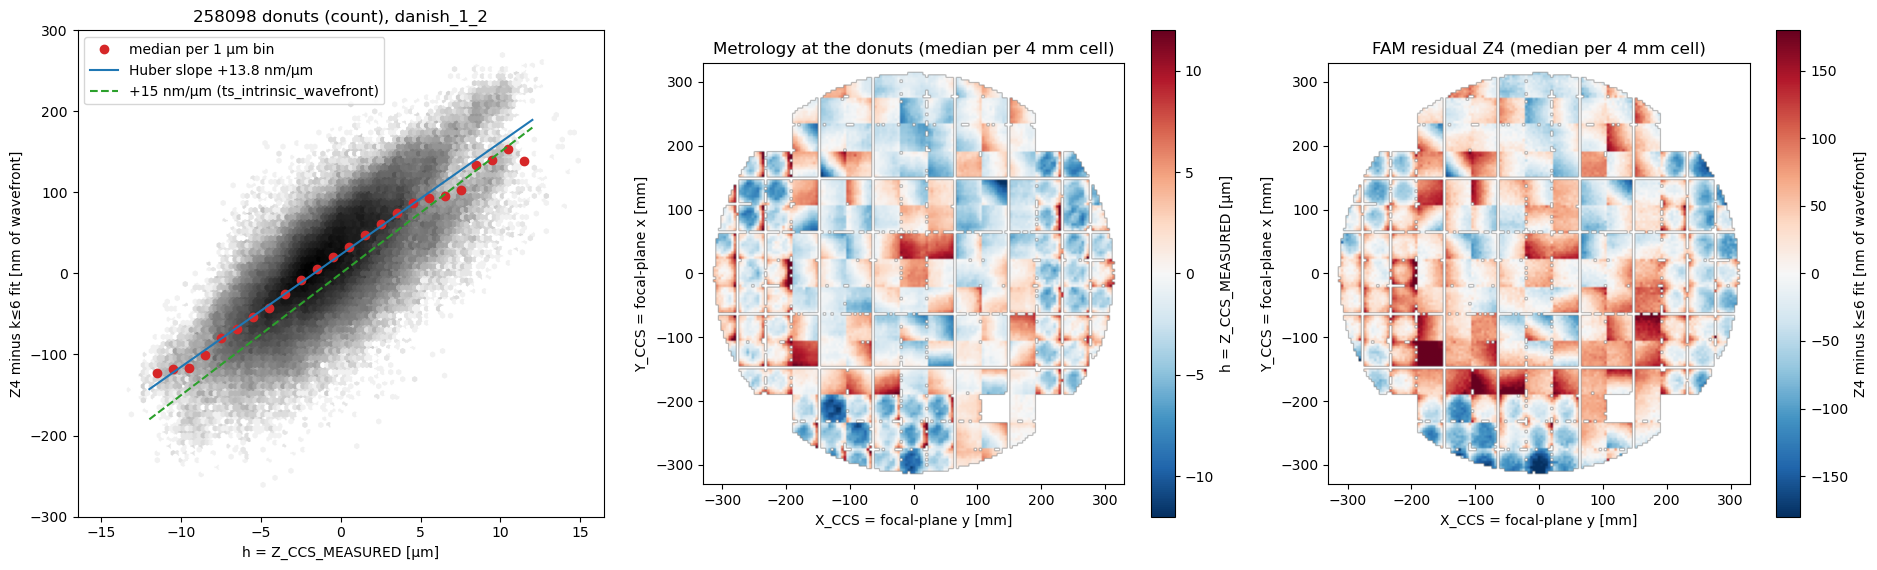

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.8))
ax[0].hexbin(don.h_um, don.z4_resid * 1e3, gridsize=120, bins='log', cmap='Greys',
             extent=(-15, 15, -300, 300))
edges = np.linspace(-12, 12, 25)
mid = 0.5 * (edges[1:] + edges[:-1])
med = [np.median(don.z4_resid[(don.h_um >= a) & (don.h_um < b)]) * 1e3
       for a, b in zip(edges[:-1], edges[1:])]
ax[0].plot(mid, med, 'o', color='C3', label='median per 1 µm bin')
ax[0].plot(edges, huber.params[0] * 1e3 + huber.params[1] * 1e3 * edges, 'C0',
           label=f'Huber slope {huber.params[1]*1e3:+.1f} nm/µm')
ax[0].plot(edges, ch.HEIGHT_TO_Z4_UM_PER_MM * edges, 'C2--', label='+15 nm/µm (ts_intrinsic_wavefront)')
ax[0].set_xlabel('h = Z_CCS_MEASURED [µm]'); ax[0].set_ylabel('Z4 minus k≤6 fit [nm of wavefront]')
ax[0].set_ylim(-300, 300); ax[0].legend(loc='upper left')
ax[0].set_title(f'{len(don)} donuts (count), {FAM_VARIANT}')

# Focal-plane maps on a 4 mm grid: metrology height and the median residual Z4.
bins = np.arange(-330, 331, 4)
def grid(x, y, v):
    H = pd.DataFrame({'ix': np.digitize(x, bins), 'iy': np.digitize(y, bins), 'v': v})
    G = H.groupby(['iy', 'ix']).v.median().unstack()
    return G.reindex(index=range(1, len(bins)), columns=range(1, len(bins)))
for a, v, lab, lim in [(ax[1], don.h_um, 'h = Z_CCS_MEASURED [µm]', 12),
                       (ax[2], don.z4_resid * 1e3, 'Z4 minus k≤6 fit [nm of wavefront]', 180)]:
    im = a.imshow(grid(don.fpy, don.fpx, v).values, origin='lower', cmap='RdBu_r', vmin=-lim,
                  vmax=lim, extent=(bins[0], bins[-1], bins[0], bins[-1]))
    fig.colorbar(im, ax=a, label=lab)
    a.set_xlabel('X_CCS = focal-plane y [mm]'); a.set_ylabel('Y_CCS = focal-plane x [mm]')
ax[1].set_title('Metrology at the donuts (median per 4 mm cell)')
ax[2].set_title('FAM residual Z4 (median per 4 mm cell)')
plt.tight_layout()

The measured residual Z4 rises with h: points with positive `Z_CCS_MEASURED` have more
positive Z4. From section 2, a positive Z4 change is a move away from L3 (extra-ward). So the
measured wavefronts, independent of batoid's height map, say **positive h in this file is low
(extra-ward)**, as the SW0/SW1 pistons do. The swapped-axis control loses the correlation, so it
is not an artifact of the radial field pattern. The measured slope is a little below the batoid
intrinsic's, so subtracting the batoid intrinsic slightly overcorrects the height term.

## Result

- The file and the map store Z_CCS, not Andy's image height (= −Z_CCS).
- A **negative** map value is a **high** (intra-ward) point: SW1, intra-focal, is −1.5 mm in the
  raw metrology, and the map carries the metrology sign.
- An intra-ward displacement gives **negative** Z4 (ts_wep: −1.5 mm gives Z4 ≈ −23.8 µm).
- So a high point, h < 0, should add negative Z4. `Z4_height = +15 µm/mm × h` does that, and
  batoid traced with the map agrees in sign on all 8 corner sensors, intra and extra alike,
  with batoid 5–6% larger in size.
- The FAM wavefronts agree on their own: the measured Z4 left after the k≤6 fit rises with h.
- **`ts_intrinsic_wavefront` has the right sign.** The statement to fix is in our doc: the
  term is not "extra +, intra −"; it has one sign on both sides, set by the direction of the
  height, not by which side of focus the donut is on.